<center><h1>Yu_Stella_HW7</h1></center>

Name: Stella Yu
<br>
Github Username: syu35435-cmyk
<br>
USC ID: 3420585291

## 1. Multi-class and Multi-Label Classification Using Support Vector Machines

Import packages

In [1]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC, LinearSVC
from sklearn.multiclass import OneVsRestClassifier
from sklearn.cluster import KMeans
from sklearn.metrics import calinski_harabasz_score
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline

### (a) Download the Anuran Calls (MFCCs) Data Set

In [2]:
df = pd.read_csv("../data/Frogs_MFCCs.csv")

X = df.iloc[:, :-4]
y = df[["Family", "Genus", "Species"]]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42
)

df.head()

,MFCCs_ 1,MFCCs_ 2,MFCCs_ 3,MFCCs_ 4,MFCCs_ 5,MFCCs_ 6,MFCCs_ 7,MFCCs_ 8,MFCCs_ 9,MFCCs_10,...,MFCCs_17,MFCCs_18,MFCCs_19,MFCCs_20,MFCCs_21,MFCCs_22,Family,Genus,Species,RecordID
0,1.0,0.152936,-0.105586,0.200722,0.317201,0.260764,0.100945,-0.150063,-0.171128,0.124676,...,-0.108351,-0.077623,-0.009568,0.057684,0.118680,0.014038,Leptodactylidae,Adenomera,AdenomeraAndre,1
1,1.0,0.171534,-0.098975,0.268425,0.338672,0.268353,0.060835,-0.222475,-0.207693,0.170883,...,-0.090974,-0.056510,-0.035303,0.020140,0.082263,0.029056,Leptodactylidae,Adenomera,AdenomeraAndre,1
2,1.0,0.152317,-0.082973,0.287128,0.276014,0.189867,0.008714,-0.242234,-0.219153,0.232538,...,-0.050691,-0.023590,-0.066722,-0.025083,0.099108,0.077162,Leptodactylidae,Adenomera,AdenomeraAndre,1
3,1.0,0.224392,0.118985,0.329432,0.372088,0.361005,0.015501,-0.194347,-0.098181,0.270375,...,-0.136009,-0.177037,-0.130498,-0.054766,-0.018691,0.023954,Leptodactylidae,Adenomera,AdenomeraAndre,1
4,1.0,0.087817,-0.068345,0.306967,0.330923,0.249144,0.006884,-0.265423,-0.172700,0.266434,...,-0.048885,-0.053074,-0.088550,-0.031346,0.108610,0.079244,Leptodactylidae,Adenomera,AdenomeraAndre,1


### (b) Train a classifier for each label

#### (i) Research

Exact match is the percentage of samples that exactly predicts all labels. 
Hamming loss is the percentage of incorrectly predicted label. 
Hamming score is the percentage of correctly predicted labels. 

#### (ii) Train a SVM for each of the labels

In [3]:
cv_folds = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)

model = Pipeline([
    ("scaler", StandardScaler()),
    ("svm", OneVsRestClassifier(SVC(kernel="rbf")))
])

parameters = {
    "svm__estimator__C": [0.01, 0.1, 1, 10, 100],
    "svm__estimator__gamma": [0.01, 0.1, 1, 10]
}

# Family
grid = GridSearchCV(
    model,
    parameters,
    scoring="accuracy",
    cv=cv_folds,
    n_jobs=-1
)

grid.fit(X_train, y_train["Family"])
svm = grid.best_estimator_

y_pred = pd.DataFrame(index=y_test.index)
y_pred["Family"] = svm.predict(X_test)

print("Best parameters:", grid.best_params_)
print("Cross-validation Error:", 1 - grid.best_score_)

# Genus
grid = GridSearchCV(
    model,
    parameters,
    scoring="accuracy",
    cv=cv_folds,
    n_jobs=-1
)

grid.fit(X_train, y_train["Genus"])
svm = grid.best_estimator_

y_pred["Genus"] = svm.predict(X_test)

print("Best parameters:", grid.best_params_)
print("Cross-validation Error:", 1 - grid.best_score_)

# Species
grid = GridSearchCV(
    model,
    parameters,
    scoring="accuracy",
    cv=cv_folds,
    n_jobs=-1
)

grid.fit(X_train, y_train["Species"])
svm = grid.best_estimator_

y_pred["Species"] = svm.predict(X_test)

print("Best parameters:", grid.best_params_)
print("Cross-validation Error:", 1 - grid.best_score_)

exact_match = (y_test == y_pred).all(axis=1).mean()
hamming_loss = (y_test != y_pred).to_numpy().mean()
hamming_score = 1 - hamming_loss

print("Exact Match:", exact_match)
print("Hamming Loss:", hamming_loss)
print("Hamming Score:", hamming_score)

Best parameters: {'svm__estimator__C': 10, 'svm__estimator__gamma': 0.1}
Cross-validation Error: 0.009531698696708779
Best parameters: {'svm__estimator__C': 10, 'svm__estimator__gamma': 0.1}
Cross-validation Error: 0.01092177096153224
Best parameters: {'svm__estimator__C': 10, 'svm__estimator__gamma': 0.1}
Cross-validation Error: 0.011119789201300079
Exact Match: 0.9865678554886521
Hamming Loss: 0.010035510267098965
Hamming Score: 0.9899644897329011


#### (iii) Repeat 1(b)ii with L1-penalized SVMs

In [4]:
model = Pipeline([
    ("scaler", StandardScaler()),
    ("svm", LinearSVC(
        penalty="l1",
        dual=False,
        max_iter=10000,
        random_state=42
    ))
])

parameters = {
    "svm__C": [0.01, 0.1, 1, 10, 100]
}

# Family
grid = GridSearchCV(
    model,
    parameters,
    scoring="accuracy",
    cv=cv_folds,
    n_jobs=-1
)

grid.fit(X_train, y_train["Family"])
svm = grid.best_estimator_

y_pred_l1 = pd.DataFrame(index=y_test.index)
y_pred_l1["Family"] = svm.predict(X_test)

print("Family")
print("Best parameters:", grid.best_params_)
print("Cross-validation Error:", 1 - grid.best_score_)

# Genus
grid = GridSearchCV(
    model,
    parameters,
    scoring="accuracy",
    cv=cv_folds,
    n_jobs=-1
)

grid.fit(X_train, y_train["Genus"])
svm = grid.best_estimator_

y_pred_l1["Genus"] = svm.predict(X_test)

print("\nGenus")
print("Best parameters:", grid.best_params_)
print("Cross-validation Error:", 1 - grid.best_score_)

# Species
grid = GridSearchCV(
    model,
    parameters,
    scoring="accuracy",
    cv=cv_folds,
    n_jobs=-1
)

grid.fit(X_train, y_train["Species"])
svm = grid.best_estimator_

y_pred_l1["Species"] = svm.predict(X_test)

print("\nSpecies")
print("Best parameters:", grid.best_params_)
print("Cross-validation Error:", 1 - grid.best_score_)

exact_match = (y_test == y_pred_l1).all(axis=1).mean()
hamming_loss = (y_test != y_pred_l1).to_numpy().mean()
hamming_score = 1 - hamming_loss

print("\nExact Match:", exact_match)
print("Hamming Loss:", hamming_loss)
print("Hamming Score:", hamming_score)

Family
Best parameters: {'svm__C': 10}
Cross-validation Error: 0.0587770993089084

Genus
Best parameters: {'svm__C': 100}
Cross-validation Error: 0.0484485941493894

Species
Best parameters: {'svm__C': 10}
Cross-validation Error: 0.03931766543595572

Exact Match: 0.9124594719777674
Hamming Loss: 0.05697081982399259
Hamming Score: 0.9430291801760075


#### (iv) Repeat 1(b)iii by using SMOTE or any other method for imbalance

In [5]:
model = ImbPipeline([
    ("scaler", StandardScaler()),
    ("smote", SMOTE(random_state=42)),
    ("svm", LinearSVC(
        penalty="l1",
        dual=False,
        max_iter=10000,
        random_state=42
    ))
])

parameters = {
    "svm__C": [0.01, 0.1, 1, 10, 100]
}

# Family
grid = GridSearchCV(
    model,
    parameters,
    scoring="accuracy",
    cv=cv_folds,
    n_jobs=-1
)

grid.fit(X_train, y_train["Family"])
svm = grid.best_estimator_

y_pred_smote = pd.DataFrame(index=y_test.index)
y_pred_smote["Family"] = svm.predict(X_test)

print("Family")
print("Best parameters:", grid.best_params_)
print("Cross-validation Error:", 1 - grid.best_score_)

# Genus
grid = GridSearchCV(
    model,
    parameters,
    scoring="accuracy",
    cv=cv_folds,
    n_jobs=-1
)

grid.fit(X_train, y_train["Genus"])
svm = grid.best_estimator_

y_pred_smote["Genus"] = svm.predict(X_test)

print("\nGenus")
print("Best parameters:", grid.best_params_)
print("Cross-validation Error:", 1 - grid.best_score_)

# Species
grid = GridSearchCV(
    model,
    parameters,
    scoring="accuracy",
    cv=cv_folds,
    n_jobs=-1
)

grid.fit(X_train, y_train["Species"])
svm = grid.best_estimator_

y_pred_smote["Species"] = svm.predict(X_test)

print("\nSpecies")
print("Best parameters:", grid.best_params_)
print("Cross-validation Error:", 1 - grid.best_score_)

exact_match = (y_test == y_pred_smote).all(axis=1).mean()
hamming_loss = (y_test != y_pred_smote).to_numpy().mean()
hamming_score = 1 - hamming_loss

print("\nExact Match:", exact_match)
print("Hamming Loss:", hamming_loss)
print("Hamming Score:", hamming_score)

Family
Best parameters: {'svm__C': 10}
Cross-validation Error: 0.07684448862381266

Genus
Best parameters: {'svm__C': 1}
Cross-validation Error: 0.08716313231720785


C:\Users\5809s\anaconda3\Lib\site-packages\joblib\externals\loky\process_executor.py:782: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(



Species
Best parameters: {'svm__C': 10}
Cross-validation Error: 0.04189663605667582

Exact Match: 0.8536359425660027
Hamming Loss: 0.07688744789254284
Hamming Score: 0.9231125521074571


The Gaussian SVM performed best, with the highest exact match and lowest Hamming loss. The L1 SVM had lower exact match and higher Hamming loss. Adding SMOTE produced the lowest exact match and highest Hamming loss.

## 2. K-Means Clustering on a Multi-Class and Multi-Label Data Set

### (a) Use k-means clustering

In [12]:
X = df.iloc[:, :-4]
y = df[["Family", "Genus", "Species"]]

k_values = range(2, 51)
best_ks = []
cluster_labels = []

for i in range(50):
    scores = []

    for k in k_values:
        model = KMeans(n_clusters=k, n_init=10, random_state=i)
        labels = model.fit_predict(X)

        score = calinski_harabasz_score(X, labels)
        scores.append(score)

    best_score = max(scores)
    best_index = scores.index(best_score)
    best_k = k_values[best_index]
    
    model = KMeans(n_clusters=best_k, n_init=10, random_state=i)
    labels = model.fit_predict(X)

    best_ks.append(best_k)
    cluster_labels.append(labels)

print("Best ks:", best_ks)

Best ks: [2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2]


### (b) Determine which family is the majority

In [13]:
majority_results = []

for i in range(50):
    cluster_df = y.copy()
    cluster_df["Cluster"] = cluster_labels[i]

    majority_labels = []

    for k in range(best_ks[i]):
        cluster = cluster_df[cluster_df["Cluster"] == k]

        family = cluster["Family"].value_counts().idxmax()
        genus = cluster["Genus"].value_counts().idxmax()
        species = cluster["Species"].value_counts().idxmax()

        majority_labels.append([family, genus, species])

    majority_df = pd.DataFrame(
        majority_labels,
        columns=["Family", "Genus", "Species"]
    )

    majority_df.index.name = "Cluster"
    majority_results.append(majority_df)

majority_results[0]

,Family,Genus,Species
Cluster,,,
0,Leptodactylidae,Adenomera,AdenomeraHylaedactylus
1,Hylidae,Hypsiboas,HypsiboasCordobae


### (c) Calculate the average Hamming distance, Hamming score, and Hamming loss

In [15]:
hamming_distances = []
hamming_losses = []
hamming_scores = []

for i in range(50):
    y_pred_cluster = majority_results[i].loc[cluster_labels[i]].copy()
    y_pred_cluster.index = y.index

    incorrect_labels = (y != y_pred_cluster)

    hamming_distance = incorrect_labels.sum(axis=1).mean()
    hamming_loss = incorrect_labels.to_numpy().mean()
    hamming_score = 1 - hamming_loss

    hamming_distances.append(hamming_distance)
    hamming_losses.append(hamming_loss)
    hamming_scores.append(hamming_score)

print("Average Hamming Distance:", np.mean(hamming_distances))
print("Average Hamming Loss:", np.mean(hamming_losses))
print("Average Hamming Score:", np.mean(hamming_scores))

Average Hamming Distance: 0.895621959694232
Average Hamming Loss: 0.29854065323141077
Average Hamming Score: 0.7014593467685891


## 3. ISLR 12.6.2

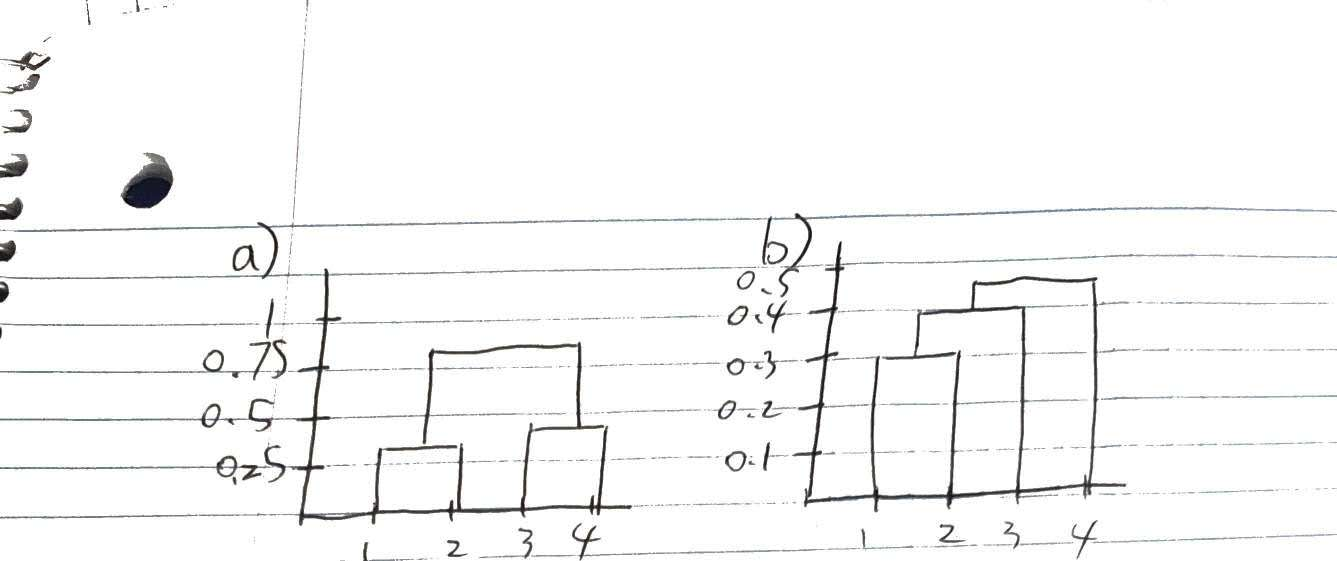
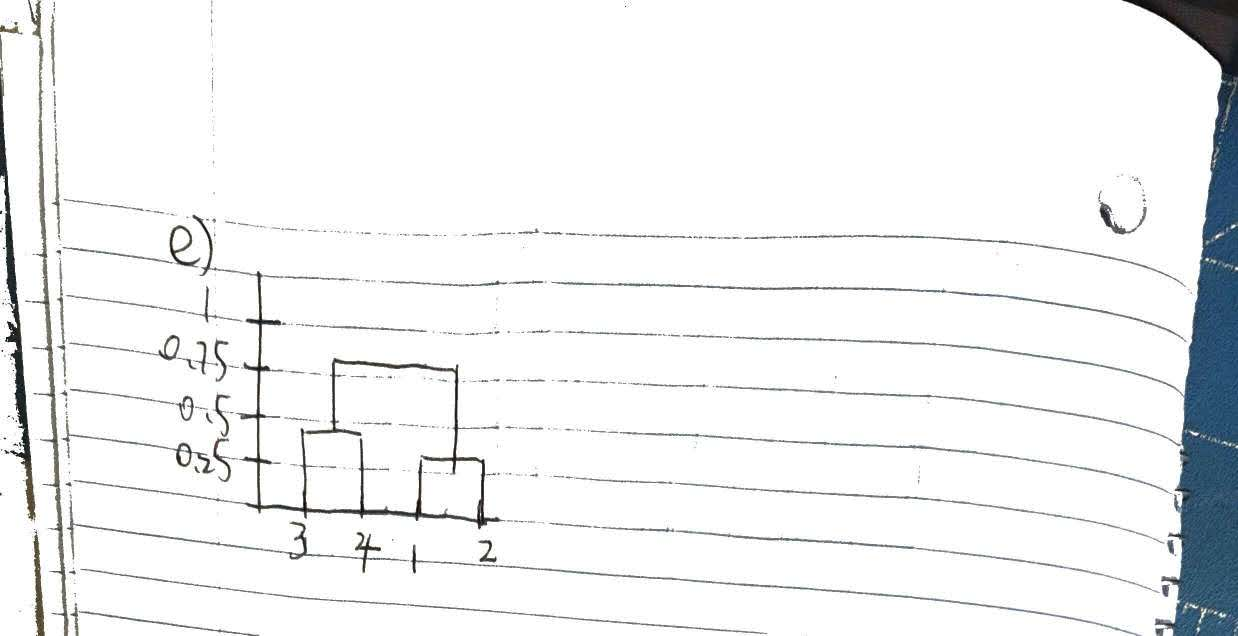

c) {1, 2}, {3, 4}
d) {1, 2, 3}, {4}